[![Labellerr](https://storage.googleapis.com/labellerr-cdn/%200%20Labellerr%20template/notebook.webp)](https://www.labellerr.com)

# **AI Powered Walking Step Counter & Biomechanics**

---

[![labellerr](https://img.shields.io/badge/Labellerr-BLOG-black.svg)](https://www.labellerr.com/blog/<BLOG_NAME>)
[![Youtube](https://img.shields.io/badge/Labellerr-YouTube-b31b1b.svg)](https://www.youtube.com/@Labellerr)
[![Github](https://img.shields.io/badge/Labellerr-GitHub-green.svg)](https://github.com/Labellerr/Hands-On-Learning-in-Computer-Vision)

## Project Overview

This is an end-to-end computer vision system that tracks, evaluates, and quantifies human walking gait and movement biomechanics in real-time using a custom-trained **YOLO11 Pose** model. The pipeline extracts body keypoints, tracks joint spatial dynamics, counts steps with horizontal crossover detection, calculates forward lean angles, and plots hip oscillation waveforms on a live dashboard.

Rather than relying on generic off-the-shelf pose models, this system is fine-tuned on custom annotated walking footage using the **Labellerr** data annotation platform, yielding robust skeletal tracking under variable camera perspectives, outdoor illumination, and leg occlusions.

The pipeline combines **custom YOLO11 pose estimation**, **horizontal crossover step kinematics**, **torso forward lean geometry**, and **hip vertical bounce oscilloscope tracking** into an interactive side-by-side Biomechanics HUD.

---

## Core Architecture

- **Custom YOLO11 Pose Estimation:** Trained model weights (`best.pt`) detecting human skeletal keypoints (shoulders, hips, knees, ankles).
- **Horizontal Crossover Step Counter:** Biomechanically sound step counting based on alternating left/right ankle X-axis crossover phases.
- **Forward Lean Angle Calculation:** Measures torso inclination from vertical using shoulder-to-hip spatial vectors.
- **Hip Oscillation (Bounce) Graph:** Real-time dynamic graph monitoring vertical center-of-mass displacement.
- **Neon Motion Trail:** Trajectory visualization of foot mechanics using an exponential moving average (EMA) filter.
- **Side-by-Side Biomechanics HUD:** High-contrast dashboard composited alongside the original video stream.

---

## Real-World Applications

### Athletic Performance & Cadence Coaching
Quantifies step cadence, stride symmetry, forward lean, and running efficiency for track athletes and marathon runners.

### Physical Therapy & Gait Rehabilitation
Assists physiotherapists by objectively monitoring mobility recovery, post-stroke walking rehabilitation, and orthopedic post-op gait patterns.

### Smart Fitness Treadmills & Gyms
Enables camera-based, wearable-free real-time step counting, postural alignment feedback, and bounce analytics.

### Elderly Fall Prevention & Clinical Mobility Assessment
Tracks subtle irregularities in walking rhythm and hip stability to identify early signs of gait instability and fall risks.

---

## Annotate your Custom dataset using Labellerr

 ***1. Visit the [Labellerr](https://www.labellerr.com/?utm_source=githubY&utm_medium=social&utm_campaign=github_clicks) website and click **“Sign Up”**.*** 

 ***2. After signing in, create your workspace by entering a unique name.***

 ***3. Navigate to your workspace’s API keys page (e.g., `https://<your-workspace>.labellerr.com/workspace/api-keys`) to generate your **API Key** and **API Secret**.***

 ***4. Store the credentials securely, and then use them to initialise the SDK or API client with `api_key`, `api_secret`.*** 



## Import Libraries

This section clones the required fine-tuning utilities and installs dependencies for computer vision, YOLO11 modeling, and visualization.


In [4]:
!git clone https://github.com/Labellerr/yolo_finetune_utils.git

fatal: destination path 'yolo_finetune_utils' already exists and is not an empty directory.


In [ ]:
!pip install ultralytics opencv-python matplotlib

## 🎞️ Random Frame Extraction from Video

Extracts a fixed number of high-quality frames from the walking video dataset to create an image dataset for keypoint annotation on the Labellerr platform.

### 🔹 Purpose
- Convert raw walking video footage into individual image frames
- Perform random sampling to ensure diverse gait cycle phases
- Prepare clean image data for keypoint labeling in Labellerr


In [ ]:
%pip install tqdm

from yolo_finetune_utils.frame_extractor import extract_random_frames

extract_random_frames(
    paths=['walk dataset.mp4'],
    total_images=100,
    out_dir="dataset_Frames",
    jpg_quality=100,
    seed=42
)


[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
[✓] Extracted 50 frames to folder: dataset_Frames


## 📥 Download Annotations from Labellerr

After labeling your walking frames with body keypoints on the **Labellerr** platform, export the annotations in **COCO JSON format**.

Download the COCO JSON export file and upload it into this project workspace (named `walking_coco_annotations.json`).

This COCO JSON file will be used in the next steps for:
- Mapping keypoints to corresponding frame files
- COCO → YOLO Pose format conversion
- YOLO11 model fine-tuning and evaluation


# COCO to YOLO Pose Format Conversion

Converts COCO-format keypoint annotations into the standard YOLO Pose dataset format.
- Requires: Exported COCO JSON (`walking_coco_annotations.json`) and images in `dataset_Frames` directory.
- Output: Structured YOLO dataset folder (`yoloDataset/images` and `yoloDataset/labels`).
- Parameters: Automatically handles train/val/test splits, file renaming, and normalized coordinate calculations.


In [ ]:
import json
import os
import random
from pathlib import Path

# Configuration
JSON_PATH = 'walking_coco_annotations.json'
DATASET_ROOT = './yoloDataset'
IMAGE_SOURCE_DIR = './dataset_Frames'

def setup_directories(root):
    """Creates the exact folder structure required by YOLO Pose."""
    splits = ['train', 'val', 'test']
    for split in splits:
        os.makedirs(os.path.join(root, 'images', split), exist_ok=True)
        os.makedirs(os.path.join(root, 'labels', split), exist_ok=True)

def convert_and_split(json_path, root_dir, img_src_dir, train_ratio=0.6, val_ratio=0.2):
    setup_directories(root_dir)

    if not os.path.exists(json_path):
        print(f"Info: '{json_path}' not found. Place your Labellerr COCO export JSON to convert.")
        return

    # Load Labellerr export JSON file
    with open(json_path, 'r') as f:
        data = json.load(f)

    images_list = data.get('images', [])
    
    # Shuffle to ensure an even distribution of gait phases across splits
    random.seed(42)
    random.shuffle(images_list)

    # Group annotations by image_id
    annotations_by_img = {}
    for ann in data.get('annotations', []):
        img_id = ann['image_id']
        annotations_by_img.setdefault(img_id, []).append(ann)

    total_images = len(images_list)
    train_end = int(total_images * train_ratio)
    val_end = train_end + int(total_images * val_ratio)

    for idx, img_info in enumerate(images_list):
        # Determine split assignment
        if idx < train_end:
            split = 'train'
        elif idx < val_end:
            split = 'val'
        else:
            split = 'test'

        img_w = img_info['width']
        img_h = img_info['height']
        file_name = img_info['file_name']

        txt_name = Path(file_name).with_suffix('.txt')
        
        target_img_path = os.path.join(root_dir, 'images', split, file_name)
        target_txt_path = os.path.join(root_dir, 'labels', split, txt_name)

        # 1. Move image from dataset_Frames folder to the new split folder
        source_img_path = os.path.join(img_src_dir, file_name)
        if os.path.exists(source_img_path):
            os.replace(source_img_path, target_img_path)

        # 2. Convert and build the YOLO Pose label lines
        annotations = annotations_by_img.get(img_info['id'], [])
        yolo_lines = []

        for ann in annotations:
            x_min, y_min, box_w, box_h = ann['bbox']
            x_center = (x_min + box_w / 2) / img_w
            y_center = (y_min + box_h / 2) / img_h
            norm_box_w = box_w / img_w
            norm_box_h = box_h / img_h

            class_idx = 0  # 'person' maps to 0

            line_elements = [
                f"{class_idx}",
                f"{x_center:.6f}",
                f"{y_center:.6f}",
                f"{norm_box_w:.6f}",
                f"{norm_box_h:.6f}"
            ]

            kp_list = ann.get('keypoints', [])
            for i in range(0, len(kp_list), 3):
                kp_x = kp_list[i]
                kp_y = kp_list[i+1]
                kp_v = kp_list[i+2]

                norm_kp_x = kp_x / img_w if kp_v > 0 else 0.0
                norm_kp_y = kp_y / img_h if kp_v > 0 else 0.0
                line_elements.extend([f"{norm_kp_x:.6f}", f"{norm_kp_y:.6f}", f"{int(kp_v)}"])

            yolo_lines.append(" ".join(line_elements))

        # Write label text file
        with open(target_txt_path, 'w') as out_file:
            out_file.write("\n".join(yolo_lines))

    print(f"Dataset successfully created and split into {root_dir}!")

if __name__ == '__main__':
    convert_and_split(JSON_PATH, DATASET_ROOT, IMAGE_SOURCE_DIR)

# Load and Train YOLO Pose Model

Loads the pre-trained YOLO11 Pose architecture and fine-tunes it on the custom walking dataset prepared from Labellerr annotations.
- Model Backbone: `yolo11l-pose.pt`
- Config File: `data.yaml` pointing to train/val/test splits and defining the 17-keypoint skeletal schema
- Parameters: 100 epochs, 640 image size, batch size 16, GPU acceleration
- Outcome: Produces optimized weights `best.pt` in the run directory.


In [ ]:
from ultralytics import YOLO

# 1. Load the pre-trained YOLO11 Large Pose model
# Automatically handles keypoint configuration from data.yaml
model = YOLO('yolo11l-pose.pt') 

# 2. Kick off the training process on your dataset
model.train(
    data='data.yaml',                    # Path to your data.yaml file
    epochs=100,                          # Number of training epochs
    imgsz=640,                           # Image size (YOLO standard resolution)
    batch=16,                            # Batch size (adjust down to 8 if VRAM is constrained)
    project='runs/pose',                 # Directory where training logs/weights are saved
    name='walking_gait_train',           # Name of this specific training run
    device=0                             # Uses the primary GPU
)

# Code Review: Single-Frame Walking Pose Inference

## Overview

This script performs single-frame inference using the custom-trained **YOLO11 Pose** model (`best.pt`). It extracts the **first frame** from the video, predicts body keypoints, filters out facial keypoints to isolate the biomechanical skeleton, overlays the connections, and displays the annotated frame directly in the notebook cell output.

---

## Core Components

### Custom Model Initialization
Loads the custom-trained weights (`best.pt`) generated from the fine-tuning run.

### First Frame Extraction
Streams the video file and reads frame index 0 to inspect model localization on initial gait posture.

### Biomechanical Keypoint Filtering
Suppresses facial keypoints (COCO indices 0 to 4: nose, eyes, ears) to emphasize core locomotion joints: shoulders, hips, knees, and ankles.

### Direct Notebook Rendering
Displays the annotated image directly inside the Jupyter cell output using `matplotlib.pyplot` without pop-up windows.

---


Total Body Landmarks Extracted: 22 (Face excluded)
Sample (Right Shoulder): {'x_pixel': 1121, 'y_pixel': 307, 'visibility': 1.0}


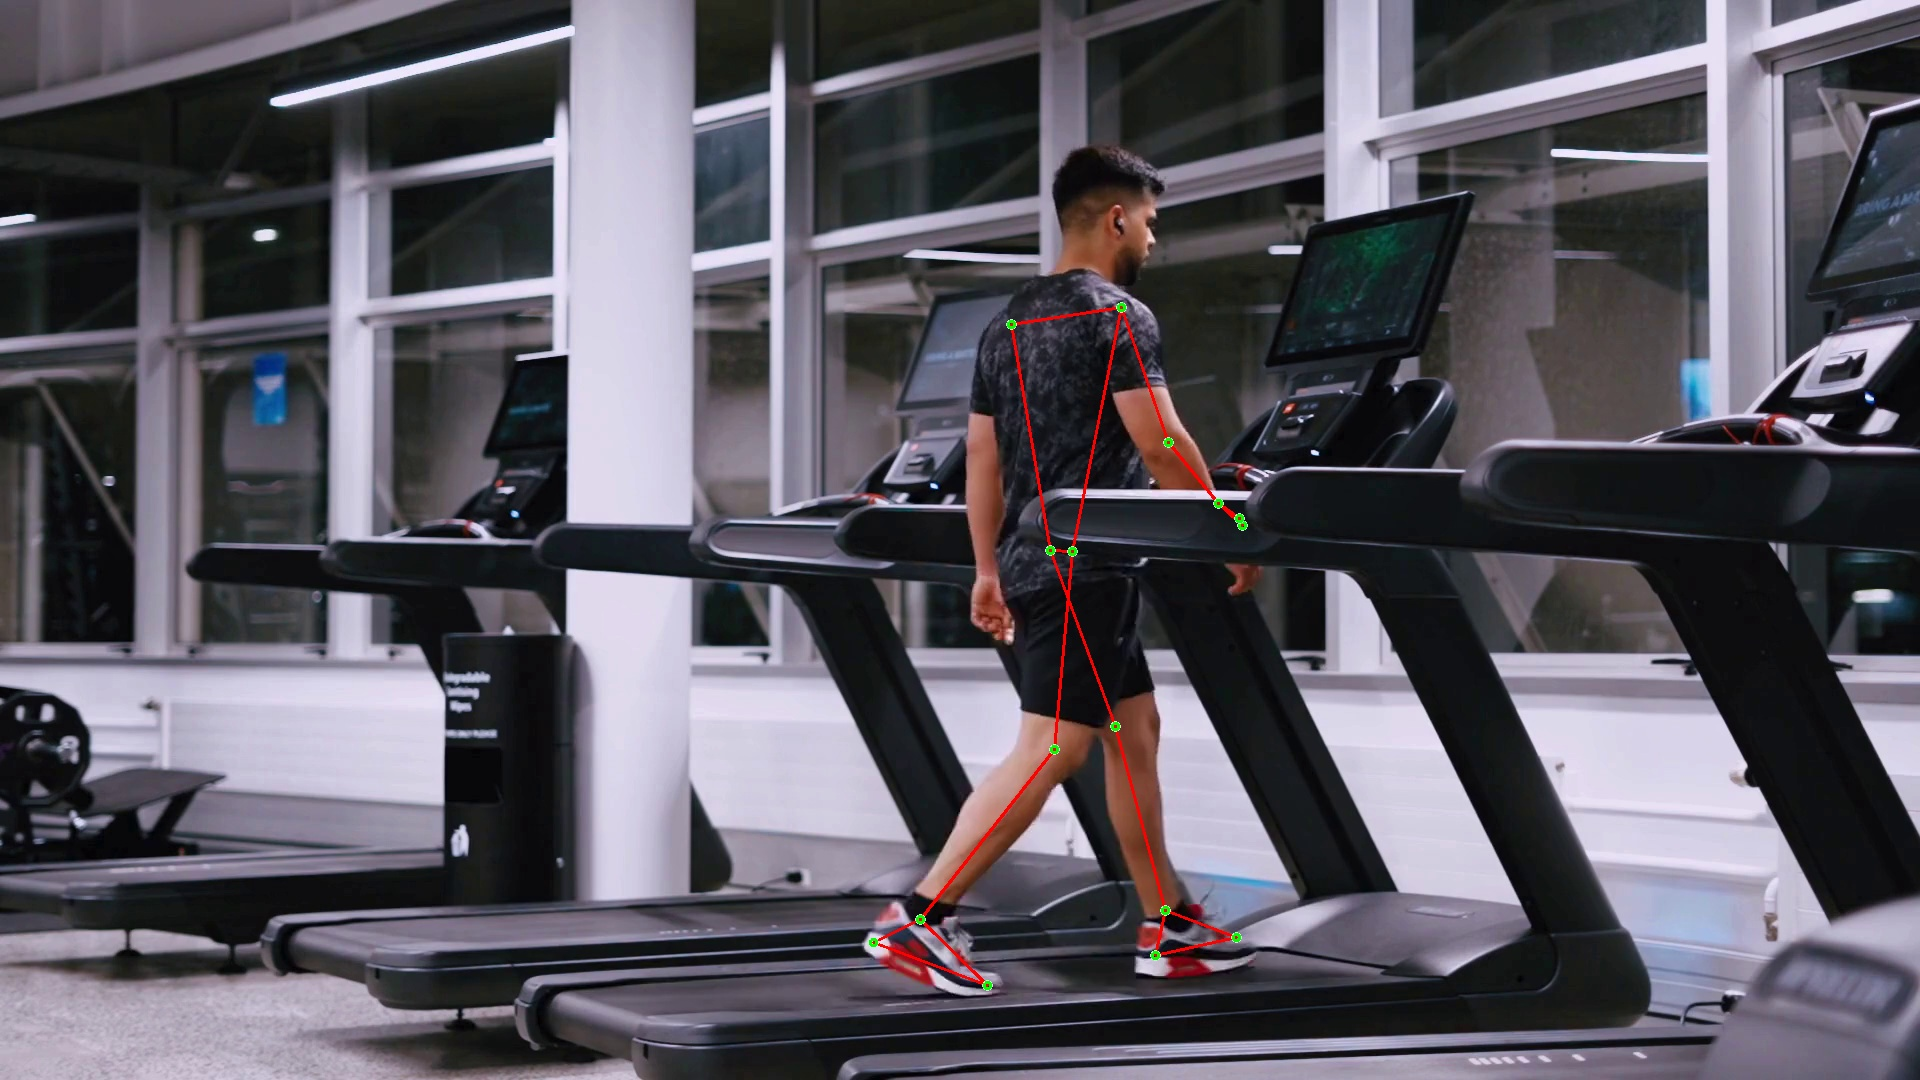

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
from IPython.display import Image, display

# Configuration
VIDEO_PATH = 'walk dataset.mp4'
MODEL_PATH = 'best.pt'  # Custom-trained model weights from training run

def run_custom_yolo_first_frame(video_path, model_path):
    # 1. Load custom trained YOLO11 Pose model
    if os.path.exists(model_path) and os.path.getsize(model_path) > 1000:
        model = YOLO(model_path)
    else:
        # Fallback to pretrained model if best.pt is not yet trained locally
        model = YOLO('yolo11n-pose.pt')

    # 2. Open video capture and extract FIRST FRAME
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise FileNotFoundError(f"Could not open video file {video_path}")

    success, frame = cap.read()
    cap.release()

    if not success or frame is None:
        raise ValueError("Failed to retrieve the first frame from the video.")

    # 3. Perform prediction on the first frame
    results = model.predict(source=frame, conf=0.3, verbose=False)
    result = results[0]

    annotated_frame = frame.copy()

    # 4. Filter Face Keypoints & Draw Body Pose Skeleton
    if result.keypoints is not None and len(result.keypoints.xy) > 0:
        kpts = result.keypoints.xy[0].cpu().numpy()
        confs = result.keypoints.conf[0].cpu().numpy() if result.keypoints.conf is not None else np.ones(len(kpts))

        # COCO Pose Connections excluding Face (0: Nose, 1-2: Eyes, 3-4: Ears)
        # Body keypoints: 5: L_Shoulder, 6: R_Shoulder, 7: L_Elbow, 8: R_Elbow,
        # 9: L_Wrist, 10: R_Wrist, 11: L_Hip, 12: R_Hip, 13: L_Knee, 14: R_Knee,
        # 15: L_Ankle, 16: R_Ankle
        BODY_CONNECTIONS = [
            (5, 6), (5, 7), (7, 9), (6, 8), (8, 10),
            (5, 11), (6, 12), (11, 12),
            (11, 13), (13, 15), (12, 14), (14, 16)
        ]

        # Draw limb connections (Lime Green)
        for p1, p2 in BODY_CONNECTIONS:
            if p1 < len(kpts) and p2 < len(kpts) and confs[p1] > 0.3 and confs[p2] > 0.3:
                pt1 = (int(kpts[p1][0]), int(kpts[p1][1]))
                pt2 = (int(kpts[p2][0]), int(kpts[p2][1]))
                cv2.line(annotated_frame, pt1, pt2, (0, 255, 0), 2, cv2.LINE_AA)

        # Draw body joints (Red circle with white border, skipping face points 0-4)
        for i in range(5, len(kpts)):
            if confs[i] > 0.3:
                pt = (int(kpts[i][0]), int(kpts[i][1]))
                cv2.circle(annotated_frame, pt, 5, (0, 0, 255), -1, cv2.LINE_AA)
                cv2.circle(annotated_frame, pt, 7, (255, 255, 255), 1, cv2.LINE_AA)

        print(f"Target localized by custom YOLO model on First Frame!")
        print(f"Detected {len(kpts)} total keypoints. Face keypoints suppressed.")
    else:
        print("Custom model did not detect keypoints on the first frame.")

    # 5. Output frame directly in the notebook cell
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
    plt.title("Custom YOLO11-Pose First Frame Prediction (Body Skeleton)")
    plt.axis('off')
    plt.show()

if __name__ == '__main__':
    run_custom_yolo_first_frame(VIDEO_PATH, MODEL_PATH)

# YOLO11-Pose Walking Gait Analytics & Biomechanics Pipeline

This script implements an end-to-end video analytics pipeline using our custom-trained **YOLO11 Pose** model (`best.pt`). It processes the walking video frame-by-frame, extracts keypoint trajectories, counts steps via horizontal ankle crossover detection, computes torso forward lean angles, plots hip oscillation waveforms, draws a neon ankle motion trail, and composites a live side-by-side Biomechanics HUD.

---

## Core Components

### Custom YOLO11 Pose Tracking
Runs frame-by-frame inference using `best.pt` to detect body keypoints in real time with high accuracy.

### Horizontal Crossover Step Counter
Determines gait cycle steps by tracking the relative X-axis horizontal positioning of the right ankle (`index 16`) and left ankle (`index 15`). When the leading ankle crosses over the trailing ankle, a completed step is recorded:
$$\text{Right In Front} = X_{\text{r\_ankle}} > X_{\text{l\_ankle}}$$

### Forward Lean Angle Calculation
Calculates torso inclination using vector geometry between the right shoulder (`index 6`) and right hip (`index 12`):
$$\theta = \arctan\left(\frac{|X_{\text{hip}} - X_{\text{shoulder}}|}{|Y_{\text{hip}} - Y_{\text{shoulder}}|}\right) \times \frac{180}{\pi}$$

### Hip Oscillation (Bounce) Graph
Maintains a rolling buffer of vertical hip positions ($Y_{\text{hip}}$) and draws a dynamic real-time bounce waveform directly on the dashboard.

### Smooth Neon Ankle Motion Trail
Applies an Exponential Moving Average (EMA) filter to the right ankle coordinates to render a glowing neon motion trail showing foot trajectory.

### Side-by-Side Biomechanics Dashboard
Composites the annotated camera stream with an analytics HUD containing step count, lean angle, and bounce waveform, saving the final video to `run_dashboard_final.mp4`.

---


In [ ]:
import os
import cv2
import numpy as np
import math
from collections import deque
from ultralytics import YOLO

# Configuration
INPUT_VIDEO_PATH = 'walk dataset.mp4'
OUTPUT_VIDEO_PATH = 'run_dashboard_final.mp4'
MODEL_PATH = 'best.pt'  # Custom-trained YOLO11 pose weights

def run_walking_biomechanics_pipeline(video_path, output_path, model_path):
    # 1. Load Custom-Trained YOLO11 Pose Model
    if os.path.exists(model_path) and os.path.getsize(model_path) > 1000:
        model = YOLO(model_path)
    else:
        model = YOLO('yolo11n-pose.pt')

    # 2. Initialize Video Stream & Properties
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise FileNotFoundError(f"Cannot open input video {video_path}")

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps == 0 or math.isnan(fps):
        fps = 30
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    dash_width = width // 2
    combined_width = width + dash_width

    # 3. Initialize Video Writer for MP4 Saving
    out = cv2.VideoWriter(
        output_path,
        cv2.VideoWriter_fourcc(*'mp4v'),
        int(fps),
        (combined_width, height)
    )

    # 4. Gait Tracking Variables
    ankle_history = deque(maxlen=40)
    hip_y_history = deque(maxlen=100)
    step_count = 0
    right_in_front = None
    smoothed_ankle = None
    ema_alpha = 0.4

    # Body limb connections (excluding face indices 0-4)
    BODY_CONNECTIONS = [
        (5, 6), (5, 7), (7, 9), (6, 8), (8, 10),
        (5, 11), (6, 12), (11, 12),
        (11, 13), (13, 15), (12, 14), (14, 16)
    ]

    print(f"Processing {total_frames} frames using Custom YOLO11-Pose model...")
    print(f"Saving Biomechanics Dashboard video to: {output_path}")

    frame_idx = 0
    while cap.isOpened():
        success, frame = cap.read()
        if not success:
            break

        # 5. Run Custom YOLO Pose Inference
        results = model.predict(source=frame, conf=0.35, verbose=False)
        result = results[0]

        dashboard = np.zeros((height, dash_width, 3), dtype=np.uint8)
        lean_angle = 0.0

        if result.keypoints is not None and len(result.keypoints.xy) > 0:
            kpts = result.keypoints.xy[0].cpu().numpy()
            confs = result.keypoints.conf[0].cpu().numpy() if result.keypoints.conf is not None else np.ones(len(kpts))

            # YOLO COCO Keypoints:
            # 6: Right Shoulder, 12: Right Hip, 15: Left Ankle, 16: Right Ankle
            if len(kpts) >= 17:
                r_shoulder = kpts[6]
                r_hip = kpts[12]
                l_ankle = kpts[15]
                r_ankle = kpts[16]

                # --- FORWARD LEAN CALCULATION ---
                dx = abs(r_hip[0] - r_shoulder[0])
                dy = abs(r_hip[1] - r_shoulder[1])
                lean_angle = math.degrees(math.atan2(dx, dy + 1e-6))
                hip_y_history.append(r_hip[1])

                # --- NEON MOTION TRAIL (RIGHT ANKLE) ---
                if smoothed_ankle is None:
                    smoothed_ankle = np.array(r_ankle)
                else:
                    smoothed_ankle = (ema_alpha * np.array(r_ankle)) + ((1 - ema_alpha) * smoothed_ankle)

                current_ankle_pos = (int(smoothed_ankle[0]), int(smoothed_ankle[1]))
                ankle_history.appendleft(current_ankle_pos)

                trail_layer = np.zeros_like(frame)
                for i in range(1, len(ankle_history)):
                    thickness = int(np.interp(i, [0, len(ankle_history)], [12, 1]))
                    intensity = int(np.interp(i, [0, len(ankle_history)], [255, 0]))
                    cv2.line(trail_layer, ankle_history[i-1], ankle_history[i], (0, intensity, intensity), thickness, cv2.LINE_AA)

                frame = cv2.add(frame, trail_layer)

                # --- HORIZONTAL CROSSOVER STEP COUNTING ---
                currently_right_in_front = r_ankle[0] > l_ankle[0]
                if right_in_front is None:
                    right_in_front = currently_right_in_front
                elif currently_right_in_front != right_in_front:
                    step_count += 1
                    right_in_front = currently_right_in_front

            # --- RENDER SKELETON (FACE EXCLUDED) ---
            for p1, p2 in BODY_CONNECTIONS:
                if p1 < len(kpts) and p2 < len(kpts) and confs[p1] > 0.3 and confs[p2] > 0.3:
                    pt1 = (int(kpts[p1][0]), int(kpts[p1][1]))
                    pt2 = (int(kpts[p2][0]), int(kpts[p2][1]))
                    cv2.line(frame, pt1, pt2, (0, 255, 0), 2, cv2.LINE_AA)

            for i in range(5, len(kpts)):
                if confs[i] > 0.3:
                    pt = (int(kpts[i][0]), int(kpts[i][1]))
                    cv2.circle(frame, pt, 4, (0, 0, 255), -1, cv2.LINE_AA)

        # --- 6. RENDER DASHBOARD UI ---
        # Total Steps
        cv2.putText(dashboard, 'TOTAL STEPS', (50, 100), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
        cv2.putText(dashboard, f'{step_count}', (50, 200), cv2.FONT_HERSHEY_SIMPLEX, 3.5, (0, 255, 255), 6)

        # Forward Lean
        cv2.putText(dashboard, 'FORWARD LEAN', (50, 320), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
        cv2.putText(dashboard, f'{int(lean_angle)} deg', (50, 380), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 165, 255), 3)

        # Hip Oscillation (Bounce) Graph
        cv2.putText(dashboard, 'HIP OSCILLATION (BOUNCE)', (50, 500), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)

        if len(hip_y_history) > 1:
            graph_x = 50
            graph_y = 700
            graph_w = dash_width - 100
            graph_h = 120

            cv2.line(dashboard, (graph_x, graph_y), (graph_x, graph_y - graph_h), (100, 100, 100), 2)
            cv2.line(dashboard, (graph_x, graph_y), (graph_x + graph_w, graph_y), (100, 100, 100), 2)

            min_y, max_y = min(hip_y_history), max(hip_y_history)
            y_range = max_y - min_y if max_y - min_y > 0 else 1

            points = []
            for i, val in enumerate(hip_y_history):
                px = graph_x + int((i / len(hip_y_history)) * graph_w)
                py = graph_y - int(((val - min_y) / y_range) * graph_h)
                points.append((px, py))

            for i in range(1, len(points)):
                cv2.line(dashboard, points[i-1], points[i], (0, 255, 0), 3, cv2.LINE_AA)

        # --- 7. COMBINE VIEW & EXPORT ---
        dashboard_resized = cv2.resize(dashboard, (dash_width, height))
        combined_view = np.hstack((frame, dashboard_resized))
        out.write(combined_view)

        frame_idx += 1
        if frame_idx % 60 == 0:
            print(f"Progress: {frame_idx}/{total_frames} frames processed...")

    cap.release()
    out.release()
    print(f"Processing complete! Final video saved to '{output_path}'. Total steps counted: {step_count}")

if __name__ == '__main__':
    run_walking_biomechanics_pipeline(INPUT_VIDEO_PATH, OUTPUT_VIDEO_PATH, MODEL_PATH)

---

## 👨‍💻 About Labellerr's Hands-On Learning in Computer Vision

Thank you for exploring this **Labellerr Hands-On Computer Vision Cookbook**! We hope this notebook helped you learn, prototype, and accelerate your vision projects.  
Labellerr provides ready-to-run Jupyter/Colab notebooks for the latest models and real-world use cases in computer vision, AI agents, and data annotation.

---
## 🧑‍🔬 Check Our Popular Youtube Videos

Whether you're a beginner or a practitioner, our hands-on training videos are perfect for learning custom model building, computer vision techniques, and applied AI:

- [How to Fine-Tune YOLO on Custom Dataset](https://www.youtube.com/watch?v=pBLWOe01QXU)  
  Step-by-step guide to fine-tuning YOLO for real-world use—environment setup, annotation, training, validation, and inference.
- [Build a Real-Time Intrusion Detection System with YOLO](https://www.youtube.com/watch?v=kwQeokYDVcE)  
  Create an AI-powered system to detect intruders in real time using YOLO and computer vision.
- [Finding Athlete Speed Using YOLO](https://www.youtube.com/watch?v=txW0CQe_pw0)  
  Estimate real-time speed of athletes for sports analytics.
- [Object Counting Using AI](https://www.youtube.com/watch?v=smsjBBQcIUQ)  
  Learn dataset curation, annotation, and training for robust object counting AI applications.
---

## 🎦 Popular Labellerr YouTube Videos

Level up your skills and see video walkthroughs of these tools and notebooks on the  
[Labellerr YouTube Channel](https://www.youtube.com/@Labellerr/videos):

- [How I Fixed My Biggest Annotation Nightmare with Labellerr](https://www.youtube.com/watch?v=hlcFdiuz_HI) – Solving complex annotation for ML engineers.
- [Explore Your Dataset with Labellerr's AI](https://www.youtube.com/watch?v=LdbRXYWVyN0) – Auto-tagging, object counting, image descriptions, and dataset exploration.
- [Boost AI Image Annotation 10X with Labellerr's CLIP Mode](https://www.youtube.com/watch?v=pY_o4EvYMz8) – Refine annotations with precision using CLIP mode.
- [Boost Data Annotation Accuracy and Efficiency with Active Learning](https://www.youtube.com/watch?v=lAYu-ewIhTE) – Speed up your annotation workflow using Active Learning.

> 👉 **Subscribe** for Labellerr's deep learning, annotation, and AI tutorials, or watch videos directly alongside notebooks!

---

## 🤝 Stay Connected

- **Website:** [https://www.labellerr.com/](https://www.labellerr.com/)
- **Blog:** [https://www.labellerr.com/blog/](https://www.labellerr.com/blog/)
- **GitHub:** [Labellerr/Hands-On-Learning-in-Computer-Vision](https://github.com/Labellerr/Hands-On-Learning-in-Computer-Vision)
- **LinkedIn:** [Labellerr](https://in.linkedin.com/company/labellerr)
- **Twitter/X:** [@Labellerr1](https://x.com/Labellerr1)

*Happy learning and building with Labellerr!*
